# Guided Exercise

In this guided exercise, we learn how to implement a Conditional Random Field (CRF) for typical image processing tasks. We will first model a problem using a CRF and then apply inference algorithms on PGMs to evaluate their performance.

Uncomment the lines in the following cell to install the required libraries and packages.

In [15]:
#!apt update
#!apt install imagemagick
#!apt install pdf2svg
#!apt install texlive texlive-latex-extra
#!apt-get install libboost-dev libboost-graph-dev libboost-program-options-dev libboost-test-dev libgmp-dev cimg-dev

#!pip install Pillow networkx
#!pip install git+https://github.com/mkrphys/ipython-tikzmagic.git
#!pip install git+https://github.com/Oriolrt/pylibdai.git
!apt-get update -qq
!apt-get install -y -qq imagemagick pdf2svg texlive texlive-latex-extra cimg-dev libboost-dev libboost-graph-dev libboost-program-options-dev libboost-test-dev libgmp-dev
%pip install -q numpy cython Pillow networkx
%pip install -q git+https://github.com/mkrphys/ipython-tikzmagic.git
%pip install -q --no-build-isolation git+https://github.com/Oriolrt/pylibdai.git
%pip install Pillow networkx
%pip install git+https://github.com/mkrphys/ipython-tikzmagic.git
%pip install git+https://github.com/Oriolrt/pylibdai.git

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/mkrphys/ipython-tikzmagic.git to /tmp/pip-req-build-l5ggxmfp
  Running command git clone --filter=blob:none --quiet https://github.com/mkrphys/ipython-tikzmagic.git /tmp/pip-req-build-l5ggxmfp
  Resolved https://github.com/mkrphys/ipython-tikzmagic.git to commit 741a199733ddb875b652a63774b696b48f67b1f4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/Oriolrt/pylibdai.git to /tmp/pip-req-build-z6wfeppa
  Running command git clone --filter=blob:none --quiet https://github.com/Oriolr

In [16]:
from dai import dai
import numpy as np
from sklearn import mixture
from PIL import Image
from time import time
import matplotlib.pyplot as plt
import os

In [17]:
%matplotlib inline

Select an image from the data folder, then open it using the Image module. The code below loads the image into memory and displays it.

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
os.chdir('/content/drive/MyDrive/optimization_C2')
print(os.listdir('.'))

['2.bmp', '1.bmp', '3.bmp', '4.bmp']


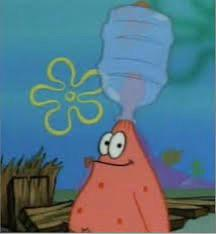

In [20]:
image = Image.open("4.bmp")
image

To assign a unary potential to each pixel we will cluster image pixels according to their colors using a Gaussian Mixture Model.

#### Exercise 1:

Fit a Gaussian Mixture Model and assign a cluster label to each pixel based on the GMM prediction. Try different values for $k$, the number of clusters of the model.

In [21]:
potential = np.asarray(image)
print(f"Size of the original image: {potential.shape}")

original_shape = potential.shape

potential = potential.reshape(
    (original_shape[0] * original_shape[1], original_shape[2])
)
print(f"Size of the unary potentials: {potential.shape}")

k = 6

# TODO:
# Train a GMM model and assign clusters based on the predictions of the GMM

clf = mixture.GaussianMixture(n_components=k, covariance_type='full', random_state=42)

clf.fit(potential)

clusters = clf.predict(potential)

mean_color = clf.means_.astype(int)

# clusters = np.ones(shape=original_shape)

segmented_image = mean_color[clusters].reshape(original_shape)
print(f"Size of the segmented image: {segmented_image.shape}")

Size of the original image: (234, 216, 3)
Size of the unary potentials: (50544, 3)
Size of the segmented image: (234, 216, 3)


In [22]:
def plot_segmentation(original_image, segmented_image, title):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(original_image)

    axes[1].set_title(title)
    axes[1].imshow(segmented_image)

    for ax in axes.ravel():
        ax.set_xticks(())
        ax.set_yticks(())

    fig.tight_layout()
    plt.show()

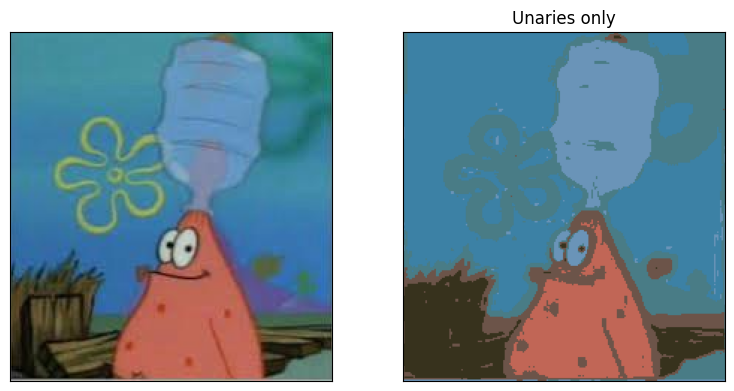

In [23]:
plot_segmentation(image, segmented_image, "Unaries only")

## Inference functions

The following cell defines a function to perform inference on a more complex model based on some parameters.

In [24]:
def inference(factor_list, method, variant):
    props = {
        "inference": variant,
        "updates": "SEQRND",
        "tol": "1e-6",
        "maxiter": "10",
        "logdomain": "0",
        "damping": 0.1,
    }

    start = time()
    inference_result = dai(factor_list, method=method, props=props)[0]
    elapsed_time = time() - start

    segmented_image = mean_color[inference_result.astype(int)]
    segmented_image = segmented_image.reshape(original_shape)

    return segmented_image, elapsed_time

## Building the model
A key step is the construction of the factor graph representation that will represent the dependencies between random variables (represented as nodes in the graph).

We want to represent each pixel as a random variable connected to some of the adjacent pixels. Depending on the connections we want to model, we have to define a different set of factors.

### Pairwise model

The most simple connection topology is a pairwise model, in which each pixel is connected to the pixels adjacent in the vertical and horizontal directions.

We define the function **BuildPairwiseFactorGraph** that, given an image, will return a list of **factors**. Each factor is defined by a tuple of the form:  *( m , f )* , where *m* is a list of variable indices and *f* corresponds to a n-dimensional array with the factor values.

In [25]:
def BuildPairwiseFactorGraph(
    image: Image,
    num_states: int = 1,
    theta: float = 0.2,
    obs_probs: np.array = None,
):
    potential = np.asarray(image)
    original_shape = potential.shape
    n_rows = original_shape[0]
    n_cols = original_shape[1]
    n_nodes = n_rows * n_cols

    indices = np.arange(n_nodes).astype(np.int64)

    down_edges = [(i, i + 1) for i in range(n_nodes) if (i + 1) % n_rows != 0]
    right_edges = [(i, i + n_rows) for i in range(n_nodes - n_rows)]

    adj = down_edges + right_edges

    if obs_probs is not None:
        unary_factors = [([m], p) for m, p in zip(indices, obs_probs)]

    energy = theta * (np.ones(num_states) - np.eye(num_states))

    pairwise_exp = np.exp(-energy)

    pairwise_factors = [(m, pairwise_exp) for m in adj]

    factor_list = unary_factors + pairwise_factors

    return factor_list

In [26]:
factor_list = BuildPairwiseFactorGraph(image, num_states=k, obs_probs=probs, theta=4.0)

NameError: name 'probs' is not defined

In [ ]:
maxprod_image, maxprod_time = inference(factor_list, "BP", "MAXPROD")
plot_segmentation(image, maxprod_image, f"Pairwise max-product {maxprod_time:.2f}s")

In [ ]:
sumprod_image, sumprod_time = inference(factor_list, "BP", "SUMPROD")
plot_segmentation(image, sumprod_image, f"Pairwise sum-product {sumprod_time:.2f}s")

In [ ]:
gibbs_image, gibbs_time = inference(factor_list, "GIBBS", None)
plot_segmentation(image, gibbs_image, f"Pairwise Gibbs {gibbs_time:.2f}s")

#### Exercise 2:

Test different values of $k$ and $\theta$ and compare the results of the segmentation.

### Three order factor model

We can consider a stronger connection between pixels by considering factors that depend on three pixels. Note that in each set of 2 by 2 pixels we consider two different factors.

#### Exercise 3:

Define the three order factors with the corresponding energy function.

In [ ]:
def BuildThreeOrderFactorGraph(
    image: Image,
    num_states: int = 1,
    theta_c: float = 0.2,
    theta_d: float = 0.2,
    obs_probs: np.array = None,
):
    potential = np.asarray(image)
    original_shape = potential.shape
    n_rows = original_shape[0]
    n_cols = original_shape[1]
    n_nodes = n_rows * n_cols

    indices = np.arange(n_nodes).astype(np.int64)

    if obs_probs is not None:
        unary_factors = [([m], p) for m, p in zip(indices, obs_probs)]

    energy = None

    three_order_exp = np.exp(-energy)

    three_order_factors = [(m, three_order_exp) for m in adj]

    factor_list = unary_factors + three_order_factors

    return factor_list


In [ ]:
factor_list = BuildThreeOrderFactorGraph(
    image, num_states=k, obs_probs=probs, theta=4.0
)

In [ ]:
maxprod_image, maxprod_time = inference(factor_list, "BP", "MAXPROD")
plot_segmentation(image, maxprod_image, f"Three order max-product {maxprod_time:.2f}s")

In [ ]:
sumprod_image, sumprod_time = inference(factor_list, "BP", "SUMPROD")
plot_segmentation(image, sumprod_image, f"Three order sum-product {sumprod_time:.2f}s")

In [ ]:
gibbs_image, gibbs_time = inference(factor_list, "GIBBS", None)
plot_segmentation(image, gibbs_image, f"Three order Gibbs {gibbs_time:.2f}s")

#### Exercise 4:

Test different values of $k$, $\theta_c$ and $\theta_d$, and compare the results of the segmentation.